# Pneumonia Detection from Chest X-Ray Images Using CNN
## Submission 1: Dataset, Exploratory Data Analysis (EDA) and Related Work

**Course:** Artificial Intelligence
**Department:** Computer Science and Engineering, East West University
**Group:** 6

| No. | Student Name | Student ID |
|---|---|---|
| 1 | Esrat Jahan Samiya | 2023-2-60-002 |
| 2 | Sabiha Akter Chaity | 2023-2-60-057 |
| 3 | Nuzhat Faiza | 2023-3-60-216 |
| 4 | Sadia Akter Dipa | 2023-2-60-244 |

**Contents**
1. Setup
2. Part A: Dataset information
3. Part B: Exploratory data analysis
4. Part B: Findings
5. Part C: Related work summary

## 1. Setup

In [5]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)     # same random sample images every run

### Dataset folder
This notebook runs on **Kaggle** with the dataset
[Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) added as input.
The loop below finds the folder that contains `train`, `test` and `val`.

In [6]:
DATA_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "train" in dirs and "test" in dirs and "val" in dirs and "__MACOSX" not in root:
        DATA_DIR = root
        break
print("Dataset folder:", DATA_DIR)

SPLITS = ["train", "test", "val"]
CLASSES = ["NORMAL", "PNEUMONIA"]

Dataset folder: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray


## 2. Part A: Dataset information

| Item | Details |
|---|---|
| **Name** | Chest X-Ray Images (Pneumonia) |
| **Source** | Kaggle: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia |
| **Original source** | Mendeley Data: https://data.mendeley.com/datasets/rscbjbr9sj/2 |
| **Reference paper** | Kermany, D. S., Goldbaum, M., Cai, W., et al. (2018). *Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning.* Cell, 172(5), 1122–1131. |
| **Year** | 2018 |
| **Licence** | CC BY 4.0 |
| **Data type** | Real-world clinical images (not synthetic) |
| **Patients** | Children aged 1–5 years, Guangzhou Women and Children's Medical Center, China |
| **Labelling** | Graded by two expert physicians; evaluation set checked by a third expert |
| **Task type** | Binary image classification |
| **Number of classes** | 2: NORMAL and PNEUMONIA |
| **File format** | JPEG |
| **Folder structure** | `train/`, `test/`, `val/`, each with `NORMAL/` and `PNEUMONIA/` subfolders |

**Why this dataset matters.** Pneumonia is one of the leading causes of death among children under five worldwide.
Diagnosing it from a chest X-ray needs a trained radiologist, and radiologists are scarce in rural areas.
An automatic classifier could help by flagging suspicious X-rays first.
Because missing a pneumonia case is more dangerous than a false alarm, **recall for PNEUMONIA** is our most important metric.

### 2.1 Number of images in each split and class

In [7]:
def list_images(split, cls):
    folder = os.path.join(DATA_DIR, split, cls)
    return [os.path.join(folder, f) for f in os.listdir(folder)
            if f.lower().endswith((".jpeg", ".jpg", ".png"))]

rows = []
for split in SPLITS:
    normal = len(list_images(split, "NORMAL"))
    pneumonia = len(list_images(split, "PNEUMONIA"))
    rows.append({"Split": split, "NORMAL": normal, "PNEUMONIA": pneumonia, "Total": normal + pneumonia})

counts = pd.DataFrame(rows)
counts.loc[len(counts)] = ["ALL", counts["NORMAL"].sum(), counts["PNEUMONIA"].sum(), counts["Total"].sum()]
counts

,Split,NORMAL,PNEUMONIA,Total
0,train,1341,3875,5216
1,test,234,390,624
2,val,8,8,16
3,ALL,1583,4273,5856


In [8]:
total_normal = counts.iloc[-1]["NORMAL"]
total_pneumonia = counts.iloc[-1]["PNEUMONIA"]
total = counts.iloc[-1]["Total"]
print("Total images:", total)
print(f"NORMAL    : {total_normal / total * 100:.1f}%")
print(f"PNEUMONIA : {total_pneumonia / total * 100:.1f}%")

Total images: 5856
NORMAL    : 27.0%
PNEUMONIA : 73.0%


> **Note:** the Kaggle page says 5,863 files, but counting only image files gives the number above (5,856).
> The extra files are non-image files such as `.DS_Store`.

### 2.2 Image size and channels
We check the width, height and colour mode of every image.
`L` means 1-channel grayscale, `RGB` means 3 channels.

In [9]:
widths, heights, modes = [], [], []
for split in SPLITS:
    for cls in CLASSES:
        for path in list_images(split, cls):
            img = Image.open(path)
            widths.append(img.size[0])
            heights.append(img.size[1])
            modes.append(img.mode)

print("Width : min", min(widths), " max", max(widths), " average", round(sum(widths) / len(widths)))
print("Height: min", min(heights), " max", max(heights), " average", round(sum(heights) / len(heights)))
print("Grayscale images (L):", modes.count("L"))
print("Colour images (RGB) :", modes.count("RGB"))

Width : min 384  max 2916  average 1328
Height: min 127  max 2713  average 971
Grayscale images (L): 5573
Colour images (RGB) : 283


## 3. Part B: Exploratory data analysis

### 3.1 Class distribution

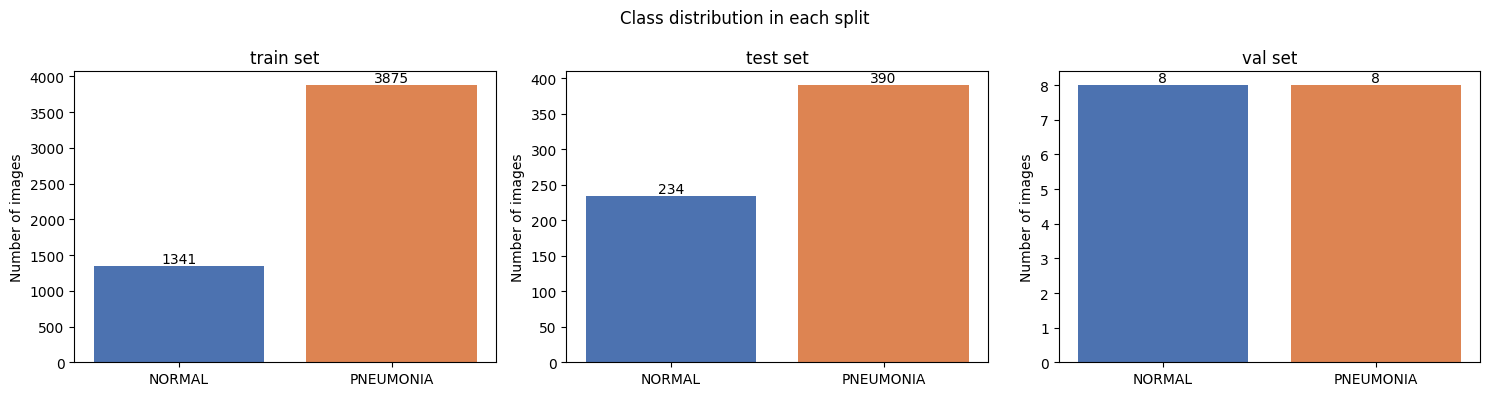

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, split in zip(axes, SPLITS):
    values = [len(list_images(split, "NORMAL")), len(list_images(split, "PNEUMONIA"))]
    bars = ax.bar(CLASSES, values, color=["#4C72B0", "#DD8452"])
    ax.bar_label(bars)
    ax.set_title(f"{split} set")
    ax.set_ylabel("Number of images")
plt.suptitle("Class distribution in each split")
plt.tight_layout()
plt.show()

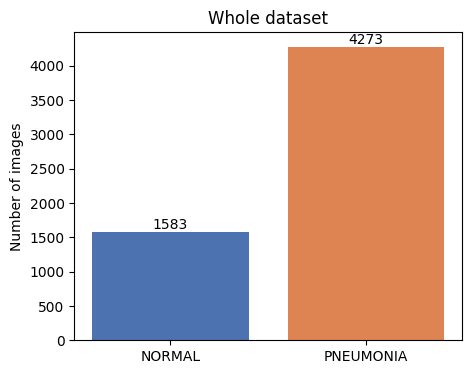

PNEUMONIA : NORMAL = 2.70 : 1
The dataset is imbalanced.


In [11]:
plt.figure(figsize=(5, 4))
bars = plt.bar(CLASSES, [total_normal, total_pneumonia], color=["#4C72B0", "#DD8452"])
plt.bar_label(bars)
plt.title("Whole dataset")
plt.ylabel("Number of images")
plt.show()

ratio = total_pneumonia / total_normal
print(f"PNEUMONIA : NORMAL = {ratio:.2f} : 1")
print("The dataset is imbalanced." if ratio > 1.5 else "The dataset is balanced.")

### 3.2 Sample images (5 per class)

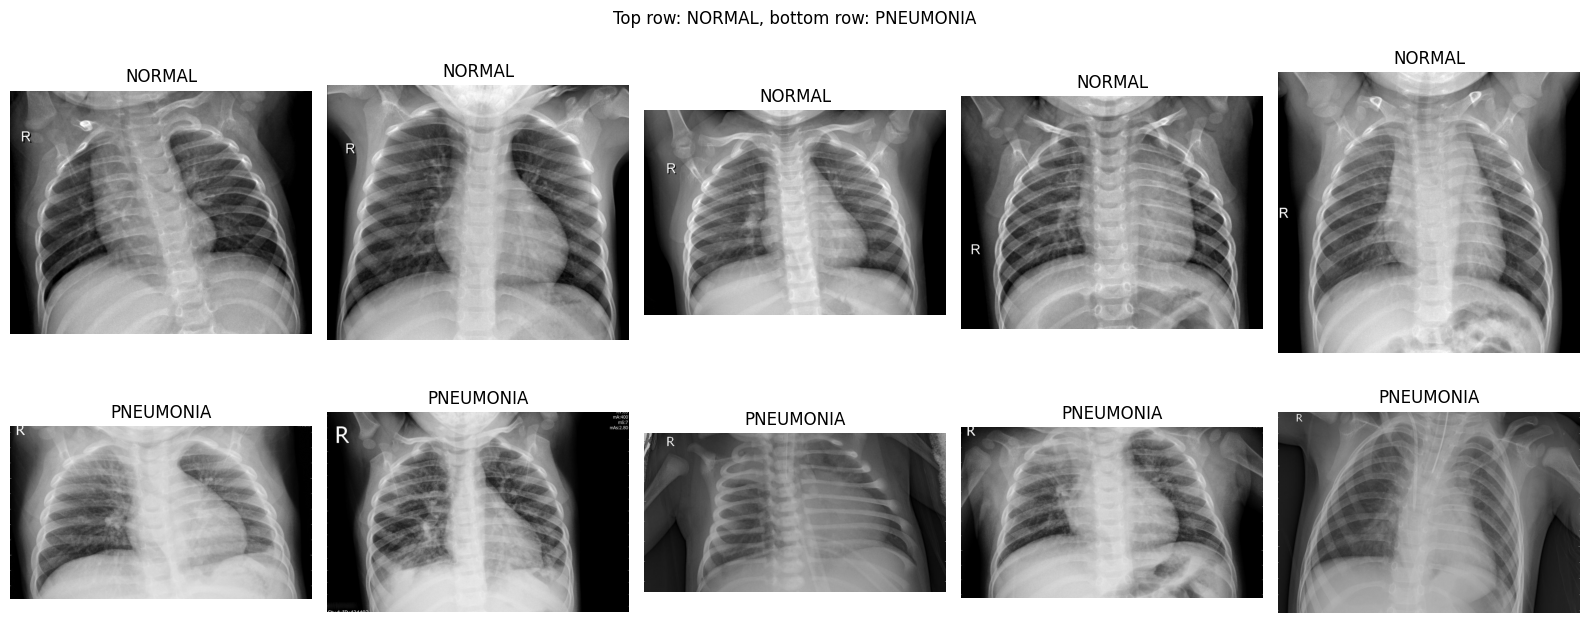

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for row, cls in enumerate(CLASSES):
    samples = random.sample(list_images("train", cls), 5)
    for col, path in enumerate(samples):
        axes[row, col].imshow(Image.open(path), cmap="gray")
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")
plt.suptitle("Top row: NORMAL, bottom row: PNEUMONIA")
plt.tight_layout()
plt.show()

## 4. Part B: Findings

**1. Class imbalance.** There are about 2.7 times more PNEUMONIA images than NORMAL images (about 73% vs 27%).
A model that always predicts PNEUMONIA would already get high accuracy, so accuracy alone is misleading.
*Plan:* use class weights, data augmentation, and report precision, recall and F1 for each class.

**2. Very small validation set.** The `val` folder has only **16 images** (8 per class), so validation accuracy is not reliable.
*Plan:* take part of the training images as a larger validation set, and keep the `test` folder only for the final evaluation.

**3. Different image sizes.** The images have very different widths and heights (see 2.2), but a CNN needs a fixed input size.
*Plan:* resize every image to 224 x 224.

**4. Grayscale and RGB mixed.** Most images are grayscale, but a few are stored as RGB.
*Plan:* convert all images to the same number of channels (3 channels for pretrained ImageNet models).

**5. Different brightness and contrast.** X-rays come from different machines.
*Plan:* normalise pixel values (for example, divide by 255).

**6. Classes look very similar, and there is noise.** NORMAL and PNEUMONIA X-rays have the same chest layout;
pneumonia shows as cloudy white areas inside the lungs (see the sample images). Some images also contain text markers and wires.
*Plan:* use mild augmentation only (small rotation and zoom), so the images still look like real X-rays.

## 5. Part C: Related work summary

All papers below use the same Kermany et al. (2018) chest X-ray dataset (or part of it).
They use different data splits, so their numbers are not directly comparable.

| # | Paper (author, year) | Dataset used | Model(s) | Approach | Result | Reference link |
|---|---|---|---|---|---|---|
| 1 | Kermany et al., 2018 (*Cell*) | Kermany paediatric CXR (original authors) | InceptionV3 | Transfer learning from ImageNet; the dataset's original benchmark | Accuracy 92.8%, Recall 93.2%, AUC 96.8% | https://doi.org/10.1016/j.cell.2018.02.010 |
| 2 | Stephen et al., 2019 (*J. Healthcare Engineering*) | Kermany CXR, re-split | Custom CNN from scratch | No transfer learning; data augmentation | Validation accuracy 93.73% | https://doi.org/10.1155/2019/4180949 |
| 3 | Liang & Zheng, 2020 (*Comput. Methods Programs Biomed.*) | Kermany paediatric CXR | Residual network with dilated convolution | Residual blocks, dilated convolution, transfer learning | Recall 96.7%, F1 92.7% | https://doi.org/10.1016/j.cmpb.2019.06.023 |
| 4 | Chouhan et al., 2020 (*Applied Sciences*) | Kermany paediatric CXR | AlexNet, DenseNet121, InceptionV3, ResNet18, GoogLeNet | Five pretrained models combined by majority voting | Accuracy 96.4%, Recall 99.62% | https://doi.org/10.3390/app10020559 |
| 5 | Rahman et al., 2020 (*Applied Sciences*) | 5,247 images from Kermany CXR | AlexNet, ResNet18, DenseNet201, SqueezeNet | Transfer learning with augmentation; DenseNet201 best | Accuracy 98%, Precision 97%, Recall 99% | https://doi.org/10.3390/app10093233 |
| 6 | Kora Venu, 2021 (*ICAART*) | Kermany paediatric CXR | Five fine-tuned CNNs | Weighted-average ensemble | Accuracy 98.46%, Recall 99.53%, F1 98.96% | https://arxiv.org/abs/2011.05543 |

**What we learn**
- Most strong results use **transfer learning** (pretrained models), which supports our Submission 2.
- A **custom CNN from scratch** can still reach about 94% (Stephen et al.), which is the target for our Submission 3.
- **Recall** is reported in almost every paper, because missing a pneumonia case is the most dangerous error.

## 6. Summary
- **Dataset:** 5,856 real paediatric chest X-ray images, 2 classes, CC BY 4.0.
- **Main issues:** class imbalance (about 73% pneumonia), only 16 validation images, different image sizes, a few RGB images, and very similar-looking classes.
- **Plan:** resize, normalise, larger validation split, class weights and mild augmentation.